# Machine Learning Foundation
## Feature Engineering with Linear Regression - Applied to the Ames Housing Data

**Data source:** Dean De Cock, Truman State University. *Journal of Statistics Education*, Volume 19, Number 3 (2011). [www.amstat.org/publications/jse/v19n3/decock.pdf](https://www.amstat.org/publications/jse/v19n3/decock.pdf)

In this notebook, we'll build linear regression models to predict housing prices. Rather than jumping straight to modeling, we'll focus on **feature engineering** - deriving new, more useful features from the data we already have. Good feature engineering is often what separates a weak model from a strong one, because it lets a simple model (like linear regression) capture patterns that wouldn't be visible in the raw features alone.

We'll use visual exploration, some domain intuition, and a few standard techniques to build progressively richer feature sets, checking along the way how each change affects model performance.

**Notebook Contents**
1. Simple EDA
2. One-hot encoding categorical variables
3. Log transformation for skewed variables
4. Pair plot for features
5. Basic feature engineering: polynomial and interaction terms
6. Feature engineering: categories and category-aggregate features
7. Scikit-learn's `PolynomialFeatures` for automatic term generation

## 1. Simple EDA

### Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
%matplotlib inline

### Load the Data

In [2]:
url = "https://raw.githubusercontent.com/wblakecannon/ames/master/data/housing.csv"
df = pd.read_csv(url, index_col=0)

print("Shape:", df.shape)
df.head()

Shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


### Examine the Columns and Missing Data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   object 
 17  House Style      29

**Reading `.info()`:** the `Non-Null Count` column tells you immediately which columns have missing data - anything less than the total row count (2,930) has missing values. `Pool QC`, `Misc Feature`, `Alley`, and `Fence` are almost entirely missing, which usually means "this feature doesn't apply" (e.g., no pool) rather than a data error.

### Remove Known Outliers

The dataset's author specifically recommends removing a few extreme outliers in `Gr Liv Area` (above-ground living area) before modeling - a small number of very large homes sold for unexpectedly low prices, which can distort a linear model. Let's visualize this, apply the fix, and keep an unmodified copy of the full data for later steps.

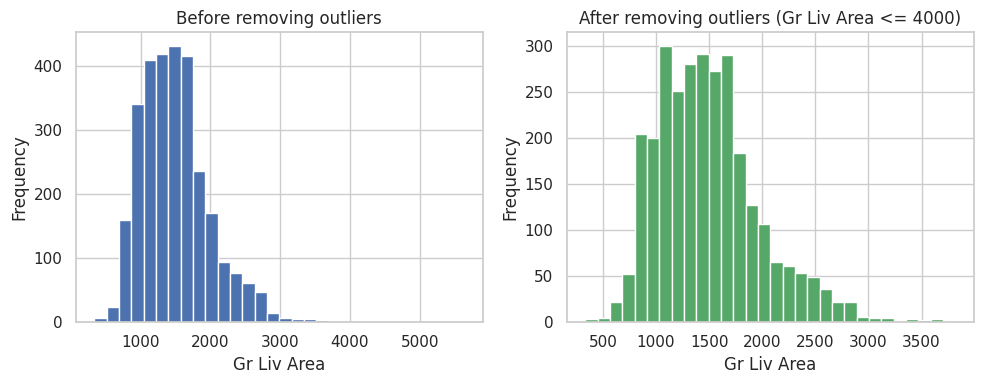

Number of rows in the data: 2925
Number of columns in the data: 82


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 4))

df["Gr Liv Area"].hist(ax=ax_before, bins=30, color="#4C72B0")
ax_before.set_title("Before removing outliers")

df = df.loc[df["Gr Liv Area"] <= 4000, :]

df["Gr Liv Area"].hist(ax=ax_after, bins=30, color="#55A868")
ax_after.set_title("After removing outliers (Gr Liv Area <= 4000)")

for ax in (ax_before, ax_after):
    ax.set_xlabel("Gr Liv Area")
    ax.set_ylabel("Frequency")

fig.tight_layout()
plt.show()

print("Number of rows in the data:", df.shape[0])
print("Number of columns in the data:", df.shape[1])

data = df.copy()  # keep an unmodified copy for later feature-engineering steps
df.head()

We're going to do two rounds of basic cleaning on this data:
1. Converting categorical variables to numeric "dummy" columns
2. Making skewed numeric variables more symmetric

Drop columns for which every value is unique     
Unique values will not add any value to the eventual model

In [6]:
print(len(df.PID.unique())) # all values are unique
print(len(df.Order.unique())) # all values are unique

2925
2925


In [7]:
# Drop
df.drop(['PID', 'Order'], axis=1, inplace=True)
df.head(3)

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000


## 2. One-Hot Encoding Variables

**Why:** linear regression needs numeric inputs. Categorical (string) columns like `Neighborhood` or `House Style` can't be plugged into the model as-is, so we convert each category into its own `0`/`1` column - this is **one-hot encoding**.

First, let's identify which columns are categorical (`dtype == object`).

In [8]:
one_hot_encode_cols = df.dtypes[df.dtypes == object]   # boolean mask -> Series of matching dtypes
one_hot_encode_cols = one_hot_encode_cols.index.tolist()  # just the column names

print(f"Found {len(one_hot_encode_cols)} categorical columns")
df[one_hot_encode_cols].head().T

Found 43 categorical columns


,0,1,2,3,4
MS Zoning,RL,RH,RL,RL,RL
Street,Pave,Pave,Pave,Pave,Pave
Alley,NaN,NaN,NaN,NaN,NaN
Lot Shape,IR1,Reg,IR1,Reg,IR1
Land Contour,Lvl,Lvl,Lvl,Lvl,Lvl
Utilities,AllPub,AllPub,AllPub,AllPub,AllPub
Lot Config,Corner,Inside,Corner,Corner,Inside
Land Slope,Gtl,Gtl,Gtl,Gtl,Gtl
Neighborhood,NAmes,NAmes,NAmes,NAmes,Gilbert
Condition 1,Norm,Feedr,Norm,Norm,Norm


Now let's apply `pd.get_dummies()` to convert those columns into `0`/`1` indicator columns. We pass `drop_first=True` to drop one category per column - this avoids redundant columns, since if a house isn't any of the *other* categories, we already know it must be the dropped one.

In [9]:
df = pd.get_dummies(df, columns=one_hot_encode_cols, drop_first=True)
print("Shape after one-hot encoding:", df.shape)
df.head()

Shape after one-hot encoding: (2925, 259)


,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,Garage Yr Blt,Garage Cars,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice,MS Zoning_C (all),MS Zoning_FV,MS Zoning_I (all),MS Zoning_RH,MS Zoning_RL,MS Zoning_RM,Street_Pave,Alley_Pave,Lot Shape_IR2,Lot Shape_IR3,Lot Shape_Reg,Land Contour_HLS,Land Contour_Low,Land Contour_Lvl,Utilities_NoSeWa,Utilities_NoSewr,Lot Config_CulDSac,Lot Config_FR2,Lot Config_FR3,Lot Config_Inside,Land Slope_Mod,Land Slope_Sev,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_Greens,Neighborhood_GrnHill,Neighborhood_IDOTRR,Neighborhood_Landmrk,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,Condition 1_Feedr,Condition 1_Norm,Condition 1_PosA,Condition 1_PosN,Condition 1_RRAe,Condition 1_RRAn,Condition 1_RRNe,Condition 1_RRNn,Condition 2_Feedr,Condition 2_Norm,Condition 2_PosA,Condition 2_PosN,Condition 2_RRAe,Condition 2_RRAn,Condition 2_RRNn,Bldg Type_2fmCon,Bldg Type_Duplex,Bldg Type_Twnhs,Bldg Type_TwnhsE,House Style_1.5Unf,House Style_1Story,House Style_2.5Fin,House Style_2.5Unf,House Style_2Story,House Style_SFoyer,House Style_SLvl,Roof Style_Gable,Roof Style_Gambrel,Roof Style_Hip,Roof Style_Mansard,Roof Style_Shed,Roof Matl_Membran,Roof Matl_Metal,Roof Matl_Roll,Roof Matl_Tar&Grv,Roof Matl_WdShake,Roof Matl_WdShngl,Exterior 1st_AsphShn,Exterior 1st_BrkComm,Exterior 1st_BrkFace,Exterior 1st_CBlock,Exterior 1st_CemntBd,Exterior 1st_HdBoard,Exterior 1st_ImStucc,Exterior 1st_MetalSd,Exterior 1st_Plywood,Exterior 1st_PreCast,Exterior 1st_Stone,Exterior 1st_Stucco,Exterior 1st_VinylSd,Exterior 1st_Wd Sdng,Exterior 1st_WdShing,Exterior 2nd_AsphShn,Exterior 2nd_Brk Cmn,Exterior 2nd_BrkFace,Exterior 2nd_CBlock,Exterior 2nd_CmentBd,Exterior 2nd_HdBoard,Exterior 2nd_ImStucc,Exterior 2nd_MetalSd,Exterior 2nd_Other,Exterior 2nd_Plywood,Exterior 2nd_PreCast,Exterior 2nd_Stone,Exterior 2nd_Stucco,Exterior 2nd_VinylSd,Exterior 2nd_Wd Sdng,Exterior 2nd_Wd Shng,Mas Vnr Type_BrkFace,Mas Vnr Type_CBlock,Mas Vnr Type_Stone,Exter Qual_Fa,Exter Qual_Gd,Exter Qual_TA,Exter Cond_Fa,Exter Cond_Gd,Exter Cond_Po,Exter Cond_TA,Foundation_CBlock,Foundation_PConc,Foundation_Slab,Foundation_Stone,Foundation_Wood,Bsmt Qual_Fa,Bsmt Qual_Gd,Bsmt Qual_Po,Bsmt Qual_TA,Bsmt Cond_Fa,Bsmt Cond_Gd,Bsmt Cond_Po,Bsmt Cond_TA,Bsmt Exposure_Gd,Bsmt Exposure_Mn,Bsmt Exposure_No,BsmtFin Type 1_BLQ,BsmtFin Type 1_GLQ,BsmtFin Type 1_LwQ,BsmtFin Type 1_Rec,BsmtFin Type 1_Unf,BsmtFin Type 2_BLQ,BsmtFin Type 2_GLQ,BsmtFin Type 2_LwQ,BsmtFin Type 2_Rec,BsmtFin Type 2_Unf,Heating_GasA,Heating_GasW,Heating_Grav,Heating_OthW,Heating_Wall,Heating QC_Fa,Heating QC_Gd,Heating QC_Po,Heating QC_TA,Central Air_Y,Electrical_FuseF,Electrical_FuseP,Electrical_Mix,Electrical_SBrkr,Kitchen Qual_Fa,Kitchen Qual_Gd,Kitchen Qual_Po,Kitchen Qual_TA,Functional_Maj2,Functional_Min1,Functional_Min2,Functional_Mod,Functional_Sal,Functional_Sev,Functional_Typ,Fireplace Qu_Fa,Fireplace Qu_Gd,Fireplace Qu_Po,Fireplace Qu_TA,Garage Type_Attchd,Garage Type_Basment,Garage Type_BuiltIn,Garage Type_CarPort,Garage Type_Detchd,Garage Finish_RFn,Garage Finish_Unf,Garage Qual_Fa,Garage Qual_Gd,Garage Qual_Po,Garage Qual_TA,Garage Cond_Fa,Garage Cond_Gd,Garage Cond_Po,Garage Cond_TA,Paved Drive_P,Paved Drive_Y,Pool QC_Fa,Pool QC_Gd,Pool QC_TA,Fence_GdWo,Fence_MnPrv,Fence_M

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MS SubClass,2925.0,57.396581,42.668752,20.0,20.00,50.0,70.00,190.0
Lot Frontage,2435.0,69.023819,22.710918,21.0,58.00,68.0,80.00,313.0
Lot Area,2925.0,10103.583590,7781.999124,1300.0,7438.00,9428.0,11515.00,215245.0
Overall Qual,2925.0,6.088205,1.402953,1.0,5.00,6.0,7.00,10.0
Overall Cond,2925.0,5.563761,1.112262,1.0,5.00,5.0,6.00,9.0
Year Built,2925.0,1971.302906,30.242474,1872.0,1954.00,1973.0,2001.00,2010.0
Year Remod/Add,2925.0,1984.234188,20.861774,1950.0,1965.00,1993.0,2004.00,2010.0
Mas Vnr Area,2902.0,100.710544,176.034290,0.0,0.00,0.0,164.00,1600.0
BsmtFin SF 1,2924.0,438.097469,438.032289,0.0,0.00,369.5,733.25,2288.0
BsmtFin SF 2,2924.0,49.807456,169.300590,0.0,0.00,0.0,0.00,1526.0


## 3. Log Transforming Skewed Variables

**Why:** linear regression works best when residuals are roughly normally distributed, and heavily skewed features can hurt that. A common fix is to apply a **log transform** to skewed numeric columns, which compresses large values and spreads out small ones, making the distribution more symmetric.

We'll work from the untouched `data` copy (before one-hot encoding) so we're only looking at genuinely numeric columns.

In [15]:
float_cols = data.columns[data.dtypes == float]
print(f"Found {len(float_cols)} float columns")
float_cols.tolist()

Found 11 float columns


['Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area']

In [16]:
skew_limit = 0.75  # threshold above which we'll treat a column as "skewed"
skew_vals = data[float_cols].skew()
skew_vals

,0
Lot Frontage,1.111071
Mas Vnr Area,2.565458
BsmtFin SF 1,0.821985
BsmtFin SF 2,4.135900
Bsmt Unf SF,0.925021
Total Bsmt SF,0.399079
Bsmt Full Bath,0.615553
Bsmt Half Bath,3.965970
Garage Yr Blt,-0.382039
Garage Cars,-0.219734


In [17]:
skew_vals.abs()

,0
Lot Frontage,1.111071
Mas Vnr Area,2.565458
BsmtFin SF 1,0.821985
BsmtFin SF 2,4.135900
Bsmt Unf SF,0.925021
Total Bsmt SF,0.399079
Bsmt Full Bath,0.615553
Bsmt Half Bath,3.965970
Garage Yr Blt,0.382039
Garage Cars,0.219734


In [20]:
skew_cols = (
    skew_vals.sort_values(ascending=False)
    .to_frame()
    .rename(columns={0: "Skew"})
    .query("abs(Skew) > @skew_limit")
)

skew_cols

,Skew
BsmtFin SF 2,4.135900
Bsmt Half Bath,3.965970
Mas Vnr Area,2.565458
Lot Frontage,1.111071
Bsmt Unf SF,0.925021
BsmtFin SF 1,0.821985


Let's see what a log transform actually does to one of these skewed columns, `BsmtFin SF 1` (finished basement square footage), before applying it everywhere.

**Note:** we use `np.log1p` (which computes `log(1 + x)`) rather than plain `np.log`, because this column contains zeros - `log(0)` is undefined, but `log1p(0) = 0` works fine.

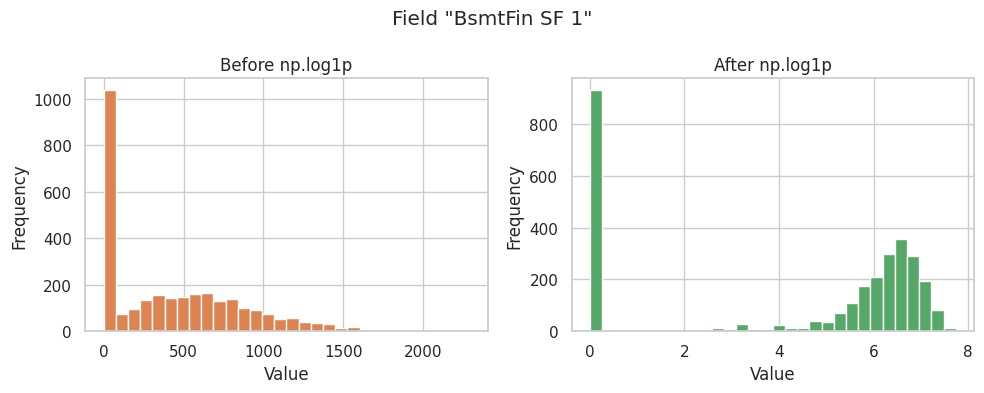

In [21]:
field = "BsmtFin SF 1"

fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 4))

df[field].hist(ax=ax_before, bins=30, color="#DD8452")
ax_before.set(title="Before np.log1p", ylabel="Frequency", xlabel="Value")

df[field].apply(np.log1p).hist(ax=ax_after, bins=30, color="#55A868")
ax_after.set(title="After np.log1p", ylabel="Frequency", xlabel="Value")

fig.suptitle(f'Field "{field}"')
fig.tight_layout()
plt.show()

Now let's apply the same transformation to every skewed column we identified (excluding `SalePrice`, which we'll keep untransformed since it's our prediction target).

In [22]:
for col in skew_cols.index.values:
    if col == "SalePrice":
        continue
    df[col] = df[col].apply(np.log1p)

print("Shape after log-transforming skewed columns:", df.shape)

Shape after log-transforming skewed columns: (2925, 259)


### Checking for Missing Values

We now have a much wider set of features thanks to one-hot encoding. Before moving further, let's go back to our original (`data`) copy and check how many values are missing per column - this determines what cleanup we still need to do.

In [23]:
missing_counts = data.isnull().sum().sort_values(ascending=False)
missing_counts.head(15)

,0
Pool QC,2914
Misc Feature,2820
Alley,2727
Fence,2354
Mas Vnr Type,1774
Fireplace Qu,1422
Lot Frontage,490
Garage Qual,159
Garage Yr Blt,159
Garage Cond,159


### A Smaller, Cleaner Subset

There are a *lot* of columns in the full dataset - many with substantial missingness (`Pool QC`, `Alley`, `Fence`, etc., which mostly mean "not applicable" rather than truly missing). To keep the rest of this notebook focused on feature engineering rather than exhaustive cleaning, let's pick out a handful of well-populated, intuitive numeric columns.

In [24]:
smaller_df = df.loc[:, [
    "Lot Area", "Overall Qual", "Overall Cond",
    "Year Built", "Year Remod/Add", "Gr Liv Area",
    "Full Bath", "Bedroom AbvGr", "Fireplaces",
    "Garage Cars", "SalePrice",
]]

smaller_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Lot Area,2925.0,10103.583590,7781.999124,1300.0,7438.0,9428.0,11515.0,215245.0
Overall Qual,2925.0,6.088205,1.402953,1.0,5.0,6.0,7.0,10.0
Overall Cond,2925.0,5.563761,1.112262,1.0,5.0,5.0,6.0,9.0
Year Built,2925.0,1971.302906,30.242474,1872.0,1954.0,1973.0,2001.0,2010.0
Year Remod/Add,2925.0,1984.234188,20.861774,1950.0,1965.0,1993.0,2004.0,2010.0
Gr Liv Area,2925.0,1493.978803,486.273646,334.0,1126.0,1441.0,1740.0,3820.0
Full Bath,2925.0,1.564786,0.551386,0.0,1.0,2.0,2.0,4.0
Bedroom AbvGr,2925.0,2.853675,0.827737,0.0,2.0,3.0,3.0,8.0
Fireplaces,2925.0,0.596923,0.645349,0.0,0.0,1.0,1.0,4.0
Garage Cars,2924.0,1.765048,0.759834,0.0,1.0,2.0,2.0,5.0


In [25]:
smaller_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2925 entries, 0 to 2929
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Lot Area        2925 non-null   int64  
 1   Overall Qual    2925 non-null   int64  
 2   Overall Cond    2925 non-null   int64  
 3   Year Built      2925 non-null   int64  
 4   Year Remod/Add  2925 non-null   int64  
 5   Gr Liv Area     2925 non-null   int64  
 6   Full Bath       2925 non-null   int64  
 7   Bedroom AbvGr   2925 non-null   int64  
 8   Fireplaces      2925 non-null   int64  
 9   Garage Cars     2924 non-null   float64
 10  SalePrice       2925 non-null   int64  
dtypes: float64(1), int64(10)
memory usage: 274.2 KB


There's one missing value in `Garage Cars`. We'll take the simple approach of filling it with `0` (i.e., assuming no garage where the value is missing).

In [26]:
smaller_df = smaller_df.fillna(0)
smaller_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2925 entries, 0 to 2929
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Lot Area        2925 non-null   int64  
 1   Overall Qual    2925 non-null   int64  
 2   Overall Cond    2925 non-null   int64  
 3   Year Built      2925 non-null   int64  
 4   Year Remod/Add  2925 non-null   int64  
 5   Gr Liv Area     2925 non-null   int64  
 6   Full Bath       2925 non-null   int64  
 7   Bedroom AbvGr   2925 non-null   int64  
 8   Fireplaces      2925 non-null   int64  
 9   Garage Cars     2925 non-null   float64
 10  SalePrice       2925 non-null   int64  
dtypes: float64(1), int64(10)
memory usage: 274.2 KB


## 4. Pair Plot of Features

Now that we have a clean, filtered dataset, a **pair plot** is a great way to visualize both the distribution of each variable and the pairwise relationships between them - all in one figure.

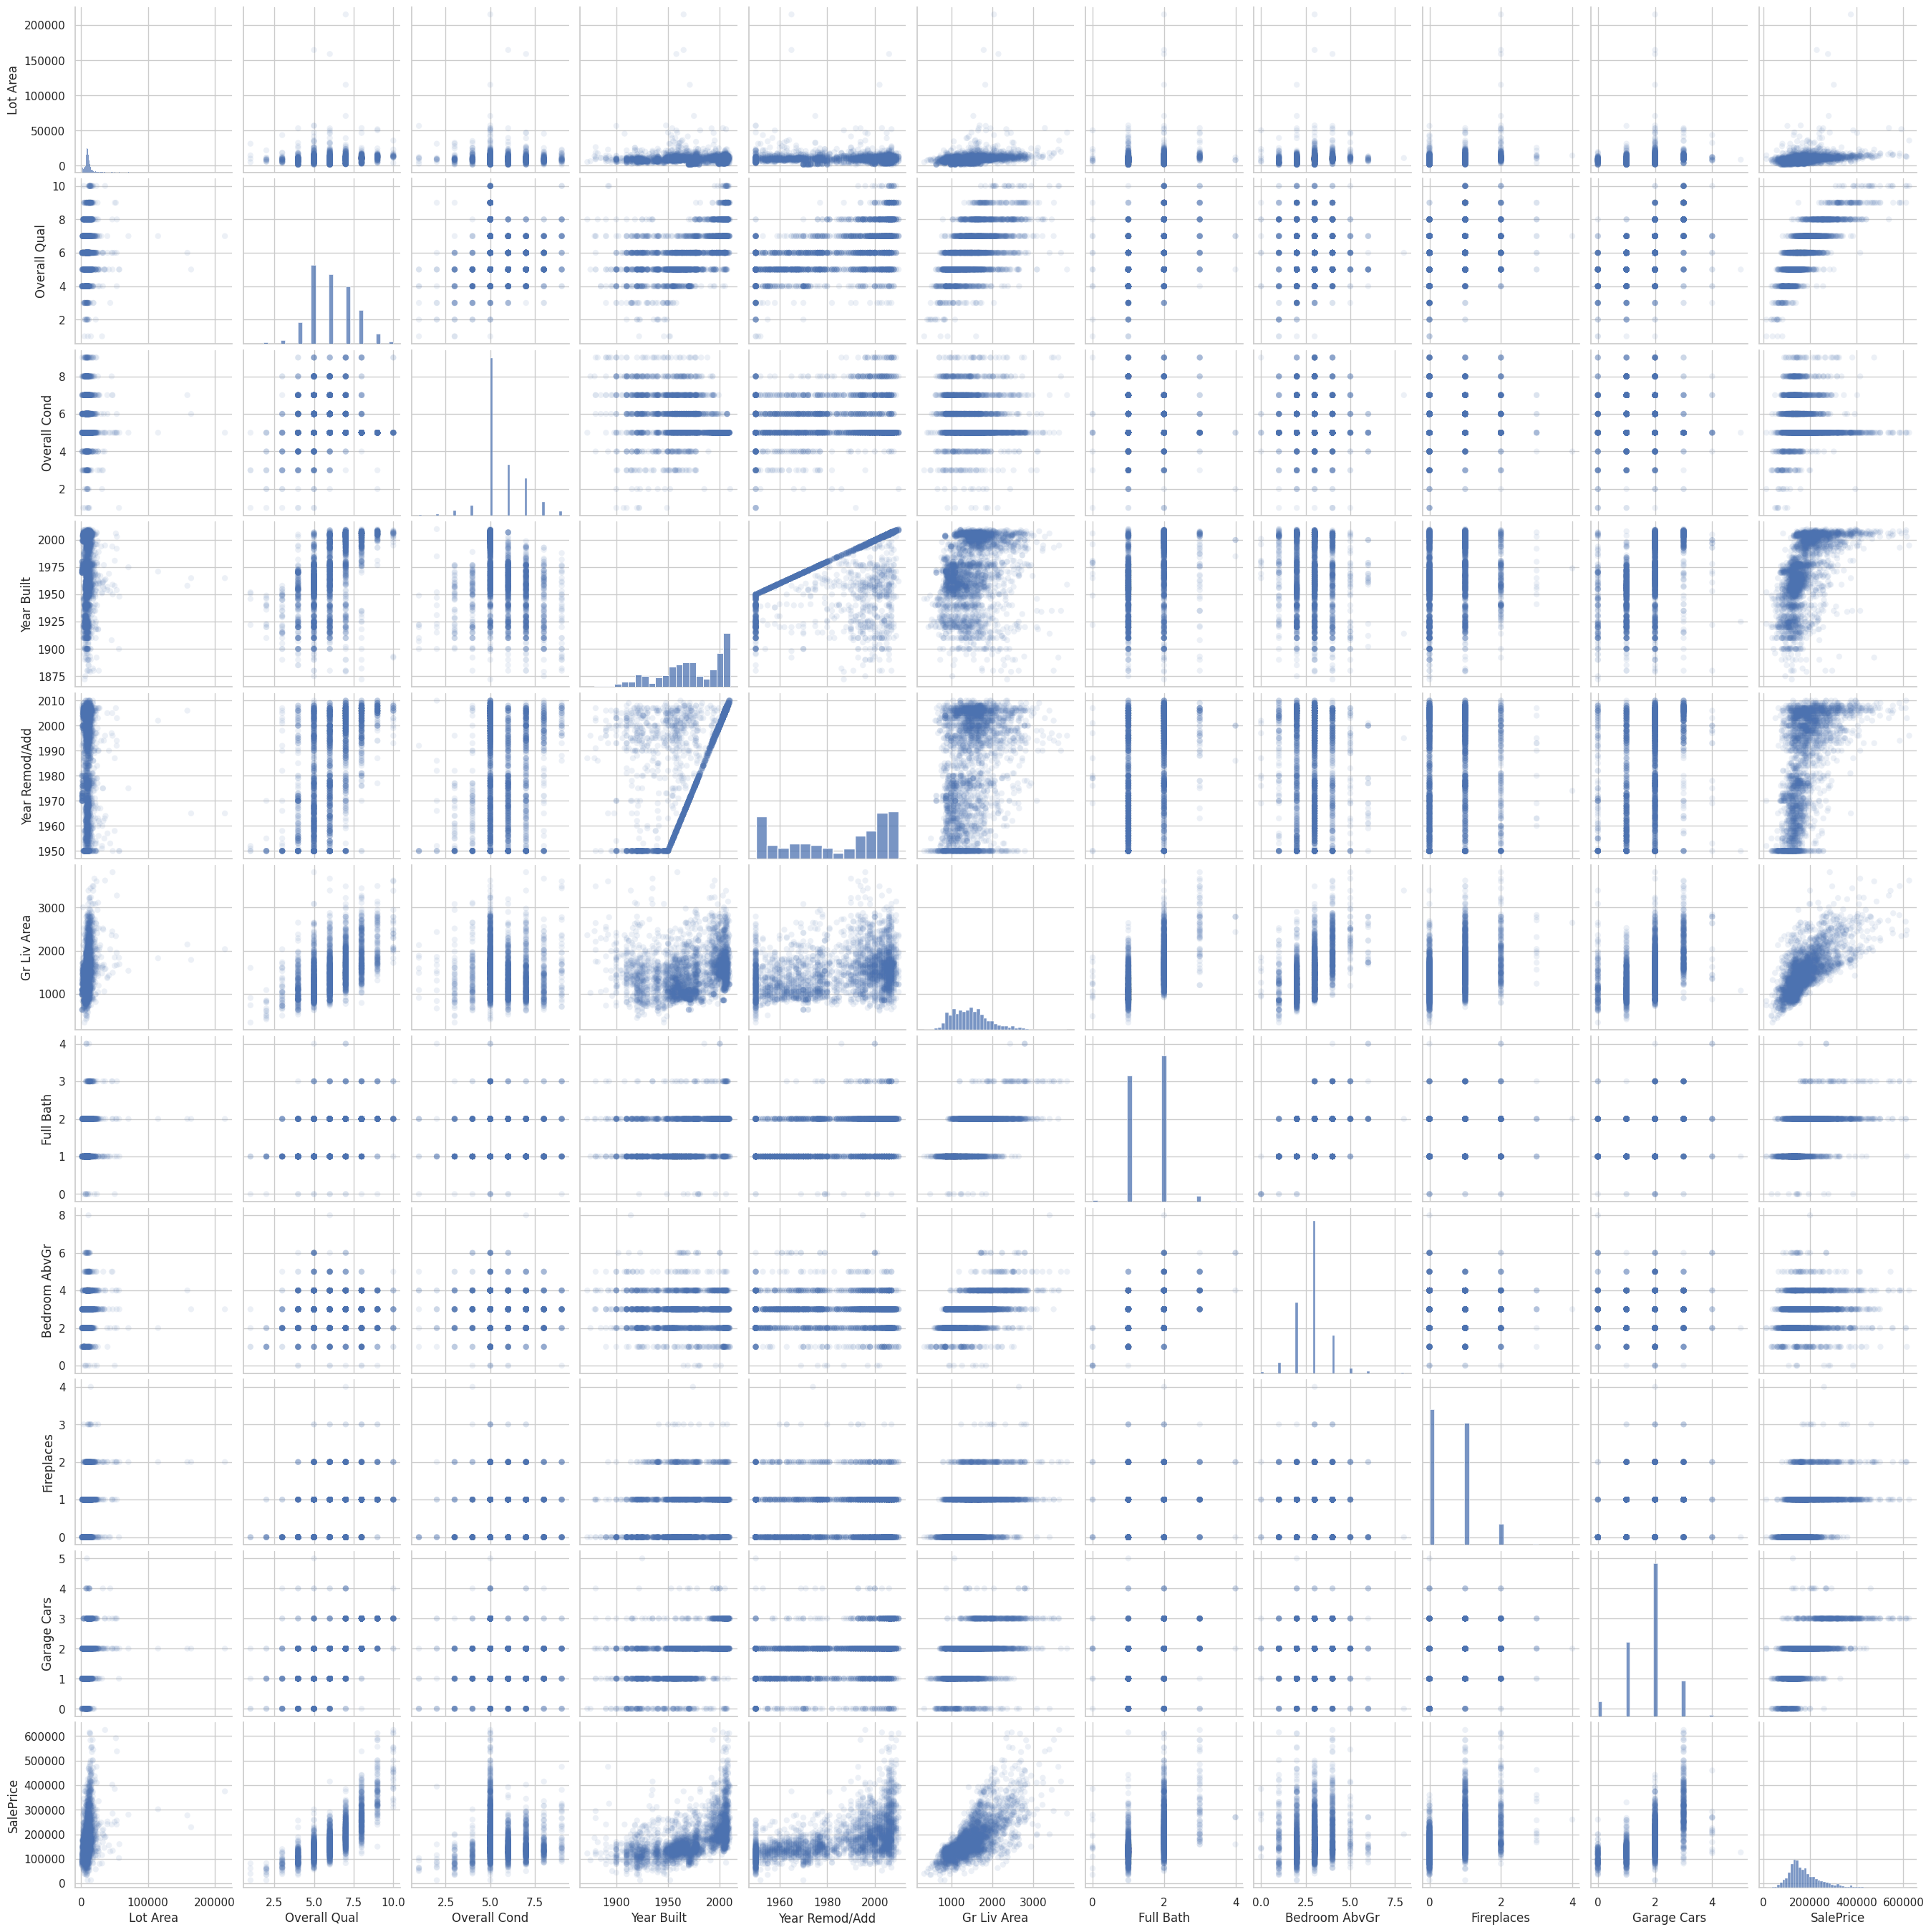

In [29]:
sns.pairplot(smaller_df, plot_kws=dict(alpha=.1, edgecolor="none"))
plt.show()

---
**Data Exploration Discussion**

1. What do these plots tell us about the distribution of the target (`SalePrice`)? *(Hint: look at the diagonal panel for `SalePrice` - is it symmetric or skewed?)*
2. What do the feature-vs-target scatter plots tell us about the relationship between each feature and `SalePrice`? Does a straight-line (linear) relationship look reasonable for all of them, or do some look curved? Which feature transformations might help?
3. What do the plots tell us about relationships *between* features (not just feature-vs-target)? Do you see pairs of features that seem to move together? Could that cause problems for a linear model? *(This is the multicollinearity question - highly correlated features can make coefficient estimates unstable.)*

---

## 5. Setting Up Features and Target

Suppose our target variable is `SalePrice`. Let's separate our features (`X`) from our target (`y`).

In [32]:
X = smaller_df.loc[:, [
    "Lot Area", "Overall Qual", "Overall Cond",
    "Year Built", "Year Remod/Add", "Gr Liv Area",
    "Full Bath", "Bedroom AbvGr", "Fireplaces",
    "Garage Cars",
]]

y = smaller_df["SalePrice"]
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2925 entries, 0 to 2929
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Lot Area        2925 non-null   int64  
 1   Overall Qual    2925 non-null   int64  
 2   Overall Cond    2925 non-null   int64  
 3   Year Built      2925 non-null   int64  
 4   Year Remod/Add  2925 non-null   int64  
 5   Gr Liv Area     2925 non-null   int64  
 6   Full Bath       2925 non-null   int64  
 7   Bedroom AbvGr   2925 non-null   int64  
 8   Fireplaces      2925 non-null   int64  
 9   Garage Cars     2925 non-null   float64
dtypes: float64(1), int64(9)
memory usage: 251.4 KB


Now that we have `X` and `y` ready, we're nearly set to fit and score a baseline linear regression model. We'll need a **train/validation split** first, so we can evaluate the model on data it hasn't seen.

Since we'll repeat this split-fit-score process every time we add new features, let's wrap it in a reusable function.

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

def split_fit_score(X, y, test_size=0.3, random_state=42):
    """Split data, fit a linear regression model, and report train/validation R^2."""
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    train_score = r2_score(y_train, model.predict(X_train))
    val_score = r2_score(y_val, model.predict(X_val))

    print(f"Train R^2: {train_score:.4f}")
    print(f"Validation R^2: {val_score:.4f}")

    return model, train_score, val_score

Let's run this on our baseline feature set and see how well plain, untransformed features do.

In [33]:
baseline_model, baseline_train, baseline_val = split_fit_score(X, y)

Train R^2: 0.8208
Validation R^2: 0.8170


**R² (coefficient of determination)** measures the proportion of variance in `SalePrice` the model explains - `1.0` is a perfect fit, `0.0` means the model does no better than predicting the mean every time. This baseline is our reference point for judging whether each new engineered feature actually helps.

## 6. Basic Feature Engineering: Polynomial and Interaction Terms

### Polynomial Features

Looking back at the pair plot, some features - like `Overall Qual` and `Gr Liv Area` - show an upward-*curving* relationship with `SalePrice`, rather than a straight line. A plain linear model can't capture that curve directly, but we can help it by adding **squared** versions of these features as new columns. The model can then learn a coefficient for both the linear and the squared term, effectively fitting a curve while still technically being "linear" (linear in its *parameters*, even though the feature itself is nonlinear).

We'll create a new copy (`X2`) so we keep `X` around as our earlier benchmark.

In [34]:
X2 = X.copy()

X2["OQ2"] = X2["Overall Qual"] ** 2
X2["GLA2"] = X2["Gr Liv Area"] ** 2

poly_model, poly_train, poly_val = split_fit_score(X2, y)

Train R^2: 0.8644
Validation R^2: 0.8651


### Feature Interactions

So far, each feature is treated independently. But there may be **interaction effects**, where the impact of one feature depends on the value of another.

For example:
- There might be a bigger "quality premium" for houses built more recently - multiplying `Overall Qual` by `Year Built` can help capture that.
- A **ratio** feature can express something like "quality per square foot" - dividing `Overall Qual` by `Lot Area`.

Let's add both and see how they affect the model.

In [38]:
X3 = X2.copy()

# Multiplicative interaction: does a quality upgrade matter more for newer homes?
X3["OQ_x_YB"] = X3["Overall Qual"] * X3["Year Built"]

# Ratio interaction: a rough "quality per unit of lot size" measure
X3["OQ_div_LA"] = X3["Overall Qual"] / X3["Lot Area"]

interaction_model, interaction_train, interaction_val = split_fit_score(X3, y)

Train R^2: 0.8744
Validation R^2: 0.8778


-----
**Interaction Feature Exercise:** What other interactions might be helpful here, and why? A few ideas to consider:
- `Gr Liv Area` × `Overall Qual` (bigger *and* nicer homes might command a disproportionate premium)
- `Fireplaces` × `Overall Qual` (a fireplace might matter more in an already high-quality home)

-----

## 7. Categories and Category-Derived Features

### One-Hot Encoding a Specific Column

Incorporating categorical features into linear regression is straightforward: create one new column per category, filled with `1`s and `0`s. Before jumping to dummy variables, it's good practice to check category counts - categories with very few observations can make coefficient estimates unstable.

In [39]:
data["House Style"].value_counts()

,count
House Style,
1Story,1480
2Story,869
1.5Fin,314
SLvl,128
SFoyer,83
2.5Unf,24
1.5Unf,19
2.5Fin,8


This looks reasonably well-distributed. Here's what the dummy-encoded version actually looks like:

In [40]:
pd.get_dummies(data["House Style"], drop_first=True).head()

,1.5Unf,1Story,2.5Fin,2.5Unf,2Story,SFoyer,SLvl
0,False,True,False,False,False,False,False
1,False,True,False,False,False,False,False
2,False,True,False,False,False,False,False
3,False,True,False,False,False,False,False
4,False,False,False,False,True,False,False


`pd.get_dummies()` can also be called on an entire dataframe at once to encode every categorical column in one step (as we did in Section 2). Let's look at another categorical feature, `Neighborhood`, which has many more distinct values.

In [47]:
nbh_counts = data["Neighborhood"].value_counts()
nbh_counts

,count
Neighborhood,
NAmes,443
CollgCr,267
OldTown,239
Edwards,191
Somerst,182
NridgHt,166
Gilbert,165
Sawyer,151
NWAmes,131


Some neighborhoods have very few homes. Rather than giving each of these a full dummy column (which risks overfitting to just a handful of rows), let's group the least-represented neighborhoods into an `"Other"` category before adding this feature.

In [43]:
other_nbhs = list(nbh_counts[nbh_counts <= 8].index)
print("Neighborhoods being grouped into 'Other':", other_nbhs)

Neighborhoods being grouped into 'Other': ['Greens', 'GrnHill', 'Landmrk']


In [44]:
X4 = X3.copy()
X4["Neighborhood"] = data["Neighborhood"].replace(other_nbhs, "Other")

In [48]:
X4["Neighborhood"].value_counts()

,count
Neighborhood,
NAmes,443
CollgCr,267
OldTown,239
Edwards,191
Somerst,182
NridgHt,166
Gilbert,165
Sawyer,151
NWAmes,131


In [49]:

# One-hot encode this new column before fitting
X4_encoded = pd.get_dummies(X4, columns=["Neighborhood"], drop_first=True)
neighborhood_model, neighborhood_train, neighborhood_val = split_fit_score(X4_encoded, y)

Train R^2: 0.8905
Validation R^2: 0.8908


### Category-Aggregate ('Deviation') Features

Let's close out with a more advanced style of feature: capturing where a value falls *relative to* the other members of its category. Specifically, we'll compute how many standard deviations a row's feature value is from the mean of its category - e.g., how much nicer a house is compared to the *average* house in its neighborhood or style.

This can pick up relative signals a raw feature value misses: a "quality 6" house might be unremarkable in one neighborhood but stand out in another.

In [25]:
def add_deviation_feature(X, feature, category):
    """Add a column measuring how many std. deviations `feature` is from its `category` mean."""
    category_gb = X.groupby(category)[feature]

    category_mean = category_gb.transform("mean")
    category_std = category_gb.transform("std")

    deviation_feature = (X[feature] - category_mean) / category_std
    X[feature + "_Dev_" + category] = deviation_feature

In [26]:
X5 = X4.copy()
X5["House Style"] = data["House Style"]

add_deviation_feature(X5, "Year Built", "House Style")
add_deviation_feature(X5, "Overall Qual", "Neighborhood")

X5.head()

,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Gr Liv Area,Full Bath,Bedroom AbvGr,Fireplaces,Garage Cars,OQ2,GLA2,OQ_x_YB,OQ_div_LA,Neighborhood,House Style,Year Built_Dev_House Style,Overall Qual_Dev_Neighborhood
0,31770,6,5,1960,1960,1656,1,3,2,2.0,36,2742336,11760,0.000189,NAmes,1Story,-0.590334,0.857503
1,11622,5,6,1961,1961,896,1,2,0,1.0,25,802816,9805,0.000430,NAmes,1Story,-0.551186,-0.430205
2,14267,6,6,1958,1958,1329,1,3,0,1.0,36,1766241,11748,0.000421,NAmes,1Story,-0.668629,0.857503
3,11160,7,5,1968,1968,2110,2,3,2,2.0,49,4452100,13776,0.000627,NAmes,1Story,-0.277154,2.145211
4,13830,5,5,1997,1998,1629,2,3,1,2.0,25,2653641,9985,0.000362,Gilbert,2Story,0.545208,-2.101974


**Note:** `X5` still has the raw `Neighborhood` and `House Style` text columns mixed in alongside our new numeric deviation features. Before fitting a model on this, those categorical columns would need one-hot encoding too (as we did for `X4` above) - this cell is here to show the deviation-feature technique clearly, not as a final, ready-to-fit feature set.

## 8. Polynomial Features in Scikit-Learn

Building squared and interaction terms by hand (as in Section 6) works, but doesn't scale well once you want *all* pairwise interactions and powers across many features. `sklearn`'s `PolynomialFeatures` automates this: given a `degree`, it generates every combination of features up to that degree, including an intercept term, the original ("degree 1") terms, squared terms, and cross-terms (interactions) between different features.

In [27]:
from sklearn.preprocessing import PolynomialFeatures

features = ["Lot Area", "Overall Qual"]

pf = PolynomialFeatures(degree=2)
pf.fit(df[features])

feat_array = pf.transform(df[features])

poly_feature_names = pf.get_feature_names_out(input_features=features)
pd.DataFrame(feat_array, columns=poly_feature_names).head()

,1,Lot Area,Overall Qual,Lot Area^2,Lot Area Overall Qual,Overall Qual^2
0,1.0,31770.0,6.0,1.009333e+09,190620.0,36.0
1,1.0,11622.0,5.0,1.350709e+08,58110.0,25.0
2,1.0,14267.0,6.0,2.035473e+08,85602.0,36.0
3,1.0,11160.0,7.0,1.245456e+08,78120.0,49.0
4,1.0,13830.0,5.0,1.912689e+08,69150.0,25.0


With `degree=2` on two input features, we get 6 output columns:
- `1` - the intercept term
- `Lot Area`, `Overall Qual` - the original features
- `Lot Area^2`, `Overall Qual^2` - squared terms
- `Lot Area Overall Qual` - the interaction (cross) term

This is the same idea as the manual `OQ2`, `GLA2`, and `OQ_x_YB` columns we built earlier - `PolynomialFeatures` just generates every such combination automatically, which is especially useful once you're working with more than a couple of features at a time.

## Summary

Across this notebook, we progressively built up our feature set and could compare each version's validation R² to judge whether it actually helped:

| Feature set | What was added |
|---|---|
| `X` (baseline) | Original numeric features only |
| `X2` | + squared terms (`Overall Qual`², `Gr Liv Area`²) |
| `X3` | + interaction terms (`Overall Qual` × `Year Built`, `Overall Qual` / `Lot Area`) |
| `X4` | + one-hot encoded `Neighborhood` (with rare categories grouped into `"Other"`) |
| `X5` | + category-deviation features (not yet encoded - for illustration) |

**Takeaways:**
- Log-transforming skewed features and removing extreme outliers helps linear regression's assumptions hold better.
- Polynomial and interaction terms let a linear model capture curved and conditional relationships without switching model types.
- One-hot encoding brings categorical information into the model, but grouping rare categories avoids overfitting to a handful of rows.
- Category-aggregate ("deviation") features can capture relative context (e.g., "nice for this neighborhood") that raw feature values miss.

------------------------------------------

| <img src="https://github.com/madhawapolkotuwa.png" width="80" style="border-radius: 50%;"> | **MPCoding**<br>*Machine Learning Tutorial Series*<br><br> [![YouTube](https://img.shields.io/badge/YouTube-%23FF0000.svg?style=for-the-badge&logo=YouTube&logoColor=white)](https://www.youtube.com/@MP-Coding) [![GitHub](https://img.shields.io/badge/github-repo-blue?logo=github)](https://github.com/madhawapolkotuwa) |
|---|---|

<p align="left" style="font-size: 0.85em; color: gray; margin-top: 10px;">
  © 2026 MPCoding. Educational materials are free to use with proper attribution.
</p>